다항회귀(PolynomialFeatures)

In [18]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier  #분류
from sklearn.neighbors import KNeighborsRegressor   #예측
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler # 정규화 클래스
from sklearn.model_selection import train_test_split

In [19]:
# 데이터 전처리 완료
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [20]:
train_data, test_data, train_label, test_label= train_test_split(perch_length,perch_weight)

In [21]:
# 2차원 배열로 변경
train_data = train_data.reshape(-1,1)
test_data=test_data.reshape(-1,1)

In [22]:
# 데이터 전처리 :다항회귀
# train_data [[43.5**2,43.5]]

train_poly = np.column_stack((train_data**2,train_data))
test_poly= np.column_stack((test_data**2,test_data))


In [23]:
# 데이터 학습
lr=LinearRegression()
lr.fit(train_poly,train_label)

# 데이터 예측
predict= lr.predict(test_poly)
print('예측데이터:',predict)
# 정확도
score= lr.score(train_poly,train_label)
score2= lr.score(test_poly,test_label)
print('train_poly:',score)
print('test_poly:',score2)


예측데이터: [ 226.54238789  706.22556123   86.46811189  112.21920584  254.23882937
   76.72377419  378.52589588 1139.42593637  706.22556123  878.9644106
  133.19653522  819.23171843  144.49260331   32.38038241]
train_poly: 0.9698722325130721
test_poly: 0.9794128968585382


In [ ]:
in_data = 25
result = lr.predict([[in_data**2,in_data]])
print("예측무게:", result)

예측무게: [1763.69662199]


In [25]:
print(lr.coef_, lr.intercept_)

[  1.07653786 -25.31379838] 169.05577774785684


In [32]:
point = np.arange(15,101)
point[:5]

array([15, 16, 17, 18, 19])

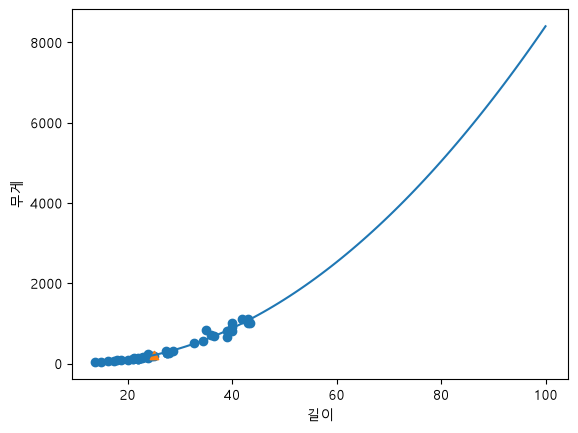

In [33]:
plt.scatter(train_data,train_label)
plt.scatter(25,208.83, marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [24]:
data= np.column_stack((perch_length,perch_weight))
data[:2]

array([[ 8.4,  5.9],
       [13.7, 32. ]])